<a href="https://colab.research.google.com/github/yiyangchen2020-afk/econ3916-problem-set-1/blob/main/Problem%20Set%201/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.


A two-earner household living in the Boston area. Both of them work full-time, they rent their home, and commute regularly for work. Their major monthly expenses are housing, food, transportation, utilities, healthcare, and other basic household needs.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [51]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Housing", "Price_2019": 1800, "Price_2024": 2400, "weight": 0.40},
    {"Item": "Food", "Price_2019": 600, "Price_2024": 750, "weight": 0.20},
    {"Item": "Transportation", "Price_2019": 500, "Price_2024": 650, "weight": 0.15},
    {"Item": "Utilities", "Price_2019": 250, "Price_2024": 320, "weight": 0.10},
    {"Item": "Healthcare", "Price_2019": 300, "Price_2024": 380, "weight": 0.10},
    {"Item": "Other", "Price_2019": 200, "Price_2024": 250, "weight": 0.05}
]

In [52]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [53]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    index = 0
    for item in basket:
        price_change = item[current_key] / item[base_key]
        index += item["weight"] * price_change
    return index * 100

In [54]:
# 1. the unweighted average price change across categories
changes = []

for item in household_basket:
    change = (item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100
    changes.append(change)

unweighted_change = sum(changes) / len(changes)
print(unweighted_change)

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")
weighted_index = laspeyres(household_basket, "Price_2019", "Price_2024")
print(weighted_index)

# 3. the gap between them
gap = weighted_index - (100 + unweighted_change)
print(gap)

28.0
129.54999999999998
1.549999999999983


**Why do the two differ, and which would you defend to the client?**


The two measures differ because the Laspeyres index gives more weight to categories that make up a larger share of the household's spending. I would use the weighted index because it better reflects the household's actual spending.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def load_fred(series_id, start="1947-01-01", end=None):
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

In [56]:
cpi = load_fred("CPIAUCSL")
rent = load_fred("CUSR0000SEHA")
food = load_fred("CUSR0000SAF11")
cars = load_fred("CUSR0000SETA02")

cpi.head()

,CPIAUCSL
date,
1947-01-01,21.48
1947-02-01,21.62
1947-03-01,22.00
1947-04-01,22.00
1947-05-01,21.95


In [57]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` |It provides a broad measure of changes in consumer prices.|It does not reflect the specific spending weights of this household.|
| `CUSR0000SEHA` |It reflects changes in rent, which is a major expense for this household.|It does not capture rent differences across specific neighborhoods or individual leases. |
| `CUSR0000SAF11` |It reflects changes in food prices for groceries, which are a regular household expense|It does not include restaurant meals or differences in what this household buys.|
| `CUSR0000SETA02` |It reflects changes in used car prices, which matter for a household that commutes regularly.|It does not capture fuel, insurance, maintenance, or public transportation costs.|

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [58]:
# Rebase to 2019 = 100
cpi_2019 = cpi[cpi.index.year == 2019].mean()
rent_2019 = rent[rent.index.year == 2019].mean()
food_2019 = food[food.index.year == 2019].mean()
cars_2019 = cars[cars.index.year == 2019].mean()
cpi_rebased = cpi / cpi_2019 * 100
rent_rebased = rent / rent_2019 * 100
food_rebased = food / food_2019 * 100
cars_rebased = cars / cars_2019 * 100

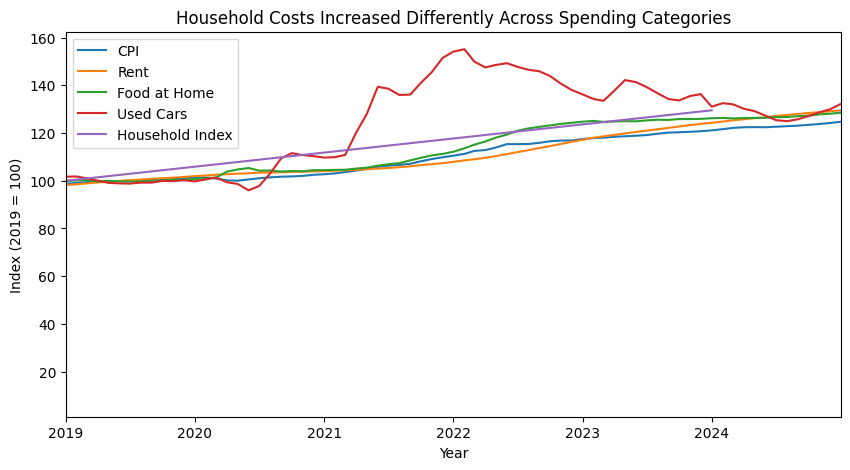

In [59]:
# One chart: every rebased series, plus your household index
# One chart: every rebased series, plus your household index
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(cpi_rebased, label="CPI")
ax.plot(rent_rebased, label="Rent")
ax.plot(food_rebased, label="Food at Home")
ax.plot(cars_rebased, label="Used Cars")

ax.plot(
    [pd.Timestamp("2019-01-01"), pd.Timestamp("2024-01-01")],
    [100, weighted_index],
    label="Household Index"
)

ax.set_xlabel("Year")
ax.set_ylabel("Index (2019 = 100)")
ax.set_title("Household Costs Increased Differently Across Spending Categories")
ax.set_xlim(pd.Timestamp("2019-01-01"), pd.Timestamp("2024-12-31"))
ax.legend()

plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [60]:
# First observation, last observation, frequency and missing months, for every series
series_dict = {
    "CPI": cpi,
    "Rent": rent,
    "Food": food,
    "Used Cars": cars
}

for name, s in series_dict.items():
    first = s.index.min()
    last = s.index.max()
    missing = s.asfreq("MS").isna().sum()

    print(name, first, last, "Monthly", missing)

for name, s in series_dict.items():
    monthly = s.asfreq("MS")
    missing_months = monthly[monthly.isna()].index

    if len(missing_months) > 0:
        print(name, missing_months)

CPI 1947-01-01 00:00:00 2026-08-01 00:00:00 Monthly 1
Rent 1981-01-01 00:00:00 2026-08-01 00:00:00 Monthly 1
Food 1952-01-01 00:00:00 2026-08-01 00:00:00 Monthly 1
Used Cars 1953-01-01 00:00:00 2026-08-01 00:00:00 Monthly 0
CPI DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Rent DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Food DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
|CPI|1947-01-01|2026-08-01|Monthly|1 (Oct 2025)|
|Rent|1981-01-01|2026-08-01|Monthly|1 (Oct 2025)|
|Food|1952-01-01|2026-08-01|Monthly|1 (Oct 2025)|
|Used Cars|1953-01-01|2026-08-01|Monthly|0|

CPI, Rent, and Food are missing October 2025 because CPI data collection was disrupted during the federal government shutdown. I will leave these observations as missing and avoid calculations that require an October 2025 value.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [61]:
# Start dates side by side, and the common sample
print(f"CPI starts: {cpi.index.min().date()}")
print(f"Rent starts: {rent.index.min().date()}")
print(f"Food starts: {food.index.min().date()}")
print(f"Used Cars starts: {cars.index.min().date()}")

common_start = max(cpi.index.min(), rent.index.min(), food.index.min(), cars.index.min())
common_end = min(cpi.index.max(), rent.index.max(), food.index.max(), cars.index.max())

common_months = len(pd.date_range(common_start, common_end, freq="MS"))
longest_months = len(cpi.asfreq("MS"))
discarded_months = longest_months - common_months

print(f"Common sample starts: {common_start.date()}")
print(f"Common sample months: {common_months}")
print(f"Months discarded from CPI: {discarded_months}")

CPI starts: 1947-01-01
Rent starts: 1981-01-01
Food starts: 1952-01-01
Used Cars starts: 1953-01-01
Common sample starts: 1981-01-01
Common sample months: 548
Months discarded from CPI: 408


In [62]:
# Headline comparison: full history vs common sample
for name, s in series_dict.items():
    full_change = (s.iloc[-1] / s.iloc[0] - 1) * 100

    common_s = s.loc[common_start:common_end]
    common_change = (common_s.iloc[-1] / common_s.iloc[0] - 1) * 100

    print(f"{name}:")
    print(f"Full history: {full_change:.1f}%")
    print(f"Common sample: {common_change:.1f}%")
    print(f"Difference: {full_change - common_change:.1f} percentage points")

CPI:
Full history: 1455.5%
Common sample: 283.2%
Difference: 1172.4 percentage points
Rent:
Full history: 430.5%
Common sample: 430.5%
Difference: 0.0 percentage points
Food:
Full history: 929.9%
Common sample: 244.0%
Difference: 685.9 percentage points
Used Cars:
Full history: 530.5%
Common sample: 157.4%
Difference: 373.1 percentage points


**What restricting to the common sample assumes, and what not restricting assumes:**


Restricting to the common sample assumes that the period since 1981 is a fair basis for comparing all four series. Not restricting assumes that differences in historical coverage do not prevent meaningful comparisons. I would use the common sample because it compares all four series over the same period.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

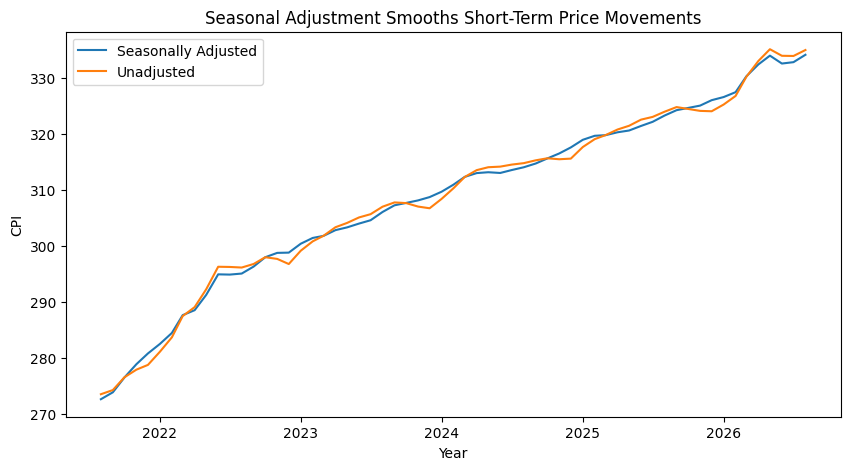

In [63]:
# Seasonally adjusted vs unadjusted, last five years
cpi_unadjusted = load_fred("CPIAUCNS")

start_5yr = cpi.index.max() - pd.DateOffset(years=5)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(cpi.loc[start_5yr:], label="Seasonally Adjusted")
ax.plot(cpi_unadjusted.loc[start_5yr:], label="Unadjusted")

ax.set_xlabel("Year")
ax.set_ylabel("CPI")
ax.set_title("Seasonal Adjustment Smooths Short-Term Price Movements")
ax.legend()

plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap reflects seasonal adjustment, which smooths recurring short-term price movements. The unadjusted series belongs in this brief because it reflects the prices workers actually face at the time they make purchases.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

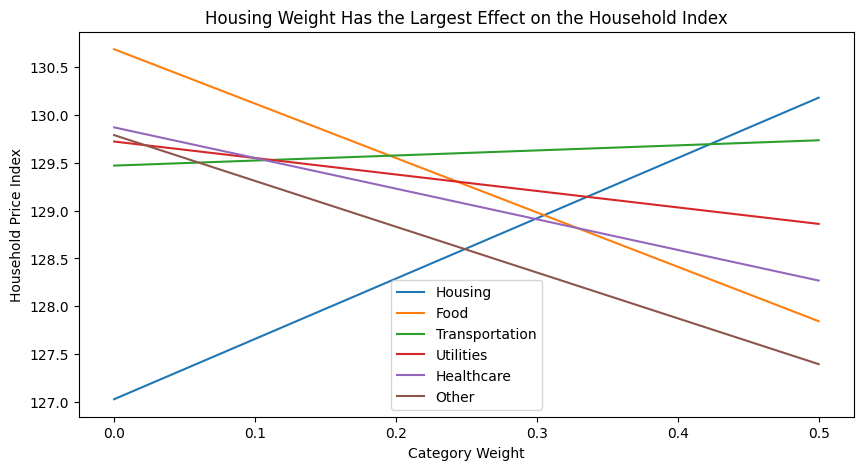

In [64]:
# Paste the AI's code here, run it, and correct it where it is wrong
weights_to_test = np.linspace(0, 0.5, 51)

results = []

for category in household_basket:
    category_name = category["Item"]

    for new_weight in weights_to_test:
        new_basket = []

        original_weight = category["weight"]
        other_weight_total = 1 - original_weight

        for item in household_basket:
            new_item = item.copy()

            if item["Item"] == category_name:
                new_item["weight"] = new_weight
            else:
                # Renormalize the other weights so all weights still sum to 1.
                new_item["weight"] = (
                    item["weight"] / other_weight_total
                ) * (1 - new_weight)

            new_basket.append(new_item)
        # If the index changes a lot, it means the result depends heavily on this category's weight.
        new_index = laspeyres(
            new_basket,
            "Price_2019",
            "Price_2024"
        )

        results.append({
            "Item": category_name,
            "weight": new_weight,
            "index": new_index
        })

results = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(10, 5))

for category in results["Item"].unique():
    data = results[results["Item"] == category]
    ax.plot(data["weight"], data["index"], label=category)

ax.set_xlabel("Category Weight")
ax.set_ylabel("Household Price Index")
ax.set_title("Housing Weight Has the Largest Effect on the Household Index")
ax.legend()

plt.show()

In [65]:
for item in results["Item"].unique():
    data = results[results["Item"] == item]
    print(item, data["index"].max() - data["index"].min())

Housing 3.1527777777777715
Food 2.843749999999986
Transportation 0.2647058823529562
Utilities 0.8611111111110858
Healthcare 1.6018518518518476
Other 2.3947368421052744


**What did the model get wrong, or get right in a way you had to check? Show the check.**

The model identified Housing as the most sensitive category. I checked this by comparing the range of the household index as each category’s weight changed from 0 to 0.5. Housing had the largest range which is about 3.15 index points, confirming the model’s conclusion.

### AI Transcript

**Model:** GPT-5.6 Sol  **Date:** October 9, 2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*


Prompt:
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.

[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.

[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.

[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.

[Evaluate] Tell me which category dominates my result and what I should say to a client about it.


### Reply

```python
weights_to_test = np.linspace(0, 0.5, 51)

results = []

for category in household_basket:
    category_name = category["Item"]

    for new_weight in weights_to_test:
        new_basket = []

        original_weight = category["weight"]
        other_weight_total = 1 - original_weight

        for item in household_basket:
            new_item = item.copy()

            if item["Item"] == category_name:
                new_item["weight"] = new_weight
            else:
                # Renormalize the other weights so all weights still sum to 1.
                new_item["weight"] = (
                    item["weight"] / other_weight_total
                ) * (1 - new_weight)

            new_basket.append(new_item)

        new_index = laspeyres(
            new_basket,
            "Price_2019",
            "Price_2024"
        )

        results.append({
            "Item": category_name,
            "weight": new_weight,
            "index": new_index
        })

results = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(10, 5))

for category in results["Item"].unique():
    data = results[results["Item"] == category]
    ax.plot(data["weight"], data["index"], label=category)

ax.set_xlabel("Category Weight")
ax.set_ylabel("Household Price Index")
ax.set_title("Housing Weight Has the Largest Effect on the Household Index")
ax.legend()

plt.show()


Renormalising the other weights is necessary because the weights must continue to sum to 1. If the index were highly sensitive to one category, the final result would depend heavily on the spending share assigned to that category.

For this household, Housing dominates the sensitivity analysis. Its price increased from 1800 to 2400, and it also has the largest original spending weight. As its weight changes, the household index moves more than it does for the other categories.

For the client, I would say that the household cost estimate is especially sensitive to housing costs. This means the conclusion is credible for this household, but it depends substantially on whether the assumed housing share accurately reflects the household's actual spending.

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

Our household price index increased by about 29.6% from 2019 to 2024. Housing was the main driver of the increase because it had the largest share of household spending, and housing prices also rose a lot. The sensitivity analysis showed the same result. Changes in the housing weight had a larger effect on the index than changes in the other categories.

This household price index is more specific than the overall CPI because it is based on the spending shares of one household. However, it is still only an estimate and does not represent the actual situation for every household. Different households can spend different amounts on rent, food, transportation, healthcare, and other expenses. The results can also change depending on the time period used and whether seasonally adjusted data are used.

I have moderate confidence in this result because the main conclusion is clear, but the result still depends on the prices and weights that I chose for the household basket. Housing has a big impact on the result, so the estimate would change if this household spent a different share of its income on rent. For this household, the results do not support the idea that CPI overstates the increase in living costs, because the household price index increased more than the overall CPI from 2019 to 2024.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub